# 20 Scikit-Learns' Tricks

In [90]:
import sklearn
import pandas as pd
import numpy as np

In [91]:
sklearn.__version__

'1.9.1'

## Trick 1: Random State

In [92]:
df = pd.read_csv('Datas/Titanic.csv')

In [93]:
x = df[['Age', 'Sex', 'Embarked']]
y = df.Survived

In [94]:
x_train, x_test, y_train, y_test = sklearn.model_selection.train_test_split(x, y, random_state=1)
x_train.head(4)

,Age,Sex,Embarked
35,42.0,male,S
46,NaN,male,Q
453,49.0,male,C
291,19.0,female,C


In [95]:
x_train, x_test, y_train, y_test = sklearn.model_selection.train_test_split(x, y, random_state=1)
x_train.head(4)

,Age,Sex,Embarked
35,42.0,male,S
46,NaN,male,Q
453,49.0,male,C
291,19.0,female,C


In [96]:
x_train, x_test, y_train, y_test = sklearn.model_selection.train_test_split(x, y, random_state=3^1000)
x_train.head(4)

,Age,Sex,Embarked
614,35.00,male,S
803,0.42,male,C
771,48.00,male,S
418,30.00,male,S


## Trick 2: Stratify

In [97]:
df = pd.DataFrame({'x' : list(range(100)), 'y' : list(['not fraud']*92 + ['fraud']*8)})
df

,x,y
0,0,not fraud
1,1,not fraud
2,2,not fraud
3,3,not fraud
4,4,not fraud
...,...,...
95,95,fraud
96,96,fraud
97,97,fraud
98,98,fraud


In [98]:
df.tail(10)

,x,y
90,90,not fraud
91,91,not fraud
92,92,fraud
93,93,fraud
94,94,fraud
95,95,fraud
96,96,fraud
97,97,fraud
98,98,fraud
99,99,fraud


In [99]:
X_train, X_test, y_train, y_test = sklearn.model_selection.train_test_split(df.x, df.y, test_size=0.5, random_state=123)

In [100]:
print(f'train: {y_train.value_counts()}')
print(f'test: {y_test.value_counts()}')

train: y
not fraud    44
fraud         6
Name: count, dtype: int64
test: y
not fraud    48
fraud         2
Name: count, dtype: int64


In [101]:
# with stratify

In [102]:
X_train, X_test, y_train, y_test = sklearn.model_selection.train_test_split(df.x, df.y, test_size=0.5, stratify=df.y, random_state=123)

In [103]:
print(f'train: {y_train.value_counts()}')
print(f'test: {y_test.value_counts()}')

train: y
not fraud    46
fraud         4
Name: count, dtype: int64
test: y
not fraud    46
fraud         4
Name: count, dtype: int64


In [104]:
# the values are not devided equally. they are devided نسبت به درصد تقسیم ترین و تست.

## Trick 3: Missing Indicator

In [105]:
df = pd.DataFrame({'Age' : [10, 20 , np.nan, 40, np.nan]})
df

,Age
0,10.0
1,20.0
2,NaN
3,40.0
4,NaN


In [106]:
imputer = sklearn.impute.SimpleImputer()

In [107]:
imputer.fit_transform(df)

array([[10.        ],
       [20.        ],
       [23.33333333],
       [40.        ],
       [23.33333333]])

In [108]:
# اندیکاتور و تمام تنظیماتی که در داده تغییر ایجاد میکنن باید توی مرحله اول ذخیره سازی کلاس انجام بشه. چون قرار هست فیت بشه.

In [109]:
imputer2 = sklearn.impute.SimpleImputer(add_indicator=True)

In [110]:
imputer2.fit_transform(df)

array([[10.        ,  0.        ],
       [20.        ,  0.        ],
       [23.33333333,  1.        ],
       [40.        ,  0.        ],
       [23.33333333,  1.        ]])

In [111]:
df2 = pd.concat([df, df], axis=1)
df2

,Age,Age
0,10.0,10.0
1,20.0,20.0
2,NaN,NaN
3,40.0,40.0
4,NaN,NaN


In [112]:
df2.columns = ['Age1', 'Age2']

In [113]:
imputer2.fit_transform(df2)

array([[10.        , 10.        ,  0.        ,  0.        ],
       [20.        , 20.        ,  0.        ,  0.        ],
       [23.33333333, 23.33333333,  1.        ,  1.        ],
       [40.        , 40.        ,  0.        ,  0.        ],
       [23.33333333, 23.33333333,  1.        ,  1.        ]])

## Trick 4 & 5: Pipeline & Columntransformer

In [114]:
knc = sklearn.neighbors.KNeighborsClassifier()
scaler = sklearn.preprocessing.StandardScaler()
num_imputer = sklearn.impute.SimpleImputer(strategy='mean')
cat_imputer = sklearn.impute.SimpleImputer(strategy='most_frequent')
ohe = sklearn.preprocessing.OneHotEncoder(drop= 'first')

In [115]:
df = pd.read_csv('Datas/Titanic.csv')

In [116]:
df.head(5)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [117]:
df.drop(['PassengerId', 'Name', 'Ticket', 'Cabin'], axis=1, inplace=True)

In [118]:
df.head(5)

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


In [119]:
df.isna().sum()

Survived      0
Pclass        0
Sex           0
Age         177
SibSp         0
Parch         0
Fare          0
Embarked      2
dtype: int64

In [120]:
num_pipe = sklearn.pipeline.Pipeline([
    ('imputer', num_imputer),
    ('scaler', scaler)
])
cat_pipe = sklearn.pipeline.Pipeline([
    ('imputer', cat_imputer),
    ('ohe', ohe)
])

In [121]:
from sklearn.compose import ColumnTransformer
transformer = ColumnTransformer([
    ('numerical', num_pipe, ['Age', 'Fare']),
    ('categorical', cat_pipe, ['Pclass', 'Sex', 'Embarked'])
], remainder='passthrough')

In [122]:
pipeline = sklearn.pipeline.Pipeline([
                                     ('transformer', transformer),
                                     ('model', knc)
                                     ])

In [123]:
x = df.drop('Survived', axis=1)
y = df.Survived

In [124]:
x_train, x_test, y_train, y_test = sklearn.model_selection.train_test_split(x, y, test_size=0.3, random_state=0)

In [125]:
pipeline.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('transformer', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['Pclass','Sex','Age',...,'Parch','Fare','Embarked']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remainin

In [126]:
pipeline.score(x_train, y_train)

0.85553772070626

In [127]:
pipeline.score(x_test, y_test)

0.7798507462686567

## Trick 6: Selecting columns for ColumnTransformer

In [128]:
#there are some ways

In [129]:
from sklearn.compose import make_column_transformer
from sklearn.compose import make_column_selector

In [130]:
from sklearn.preprocessing import OneHotEncoder

In [131]:
df = pd.read_csv('Datas/Titanic.csv')
cols = ['Age', 'Embarked', 'Sex', 'Fare']
df = df[cols]
df.head(5)

,Age,Embarked,Sex,Fare
0,22.0,S,male,7.2500
1,38.0,C,female,71.2833
2,26.0,S,female,7.9250
3,35.0,S,female,53.1000
4,35.0,S,male,8.0500


In [132]:
ohe = OneHotEncoder()

In [133]:
ct = make_column_transformer((ohe, ['Embarked', 'Sex']))
ct = make_column_transformer((ohe, [1, 2]))
ct = make_column_transformer((ohe, slice(1, 3))) # wrong : [1:3] . that works just after an iterable
ct = make_column_transformer((ohe, make_column_selector(pattern='E|S')))
ct = make_column_transformer((ohe, make_column_selector(dtype_include='object')))
ct = make_column_transformer((ohe, make_column_selector(dtype_exclude='number')))

## Trick 7: Confusion Matrix in sklearn

In [134]:
from sklearn.metrics import ConfusionMatrixDisplay

In [135]:
df = pd.read_csv('Datas/Titanic.csv')
x = df[['Fare', 'Pclass']]
y = df['Survived']

In [136]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

In [137]:
x_train, x_test, y_train, y_test = train_test_split(x, y, random_state=0, test_size=0.5, stratify=y)

In [138]:
model = LogisticRegression().fit(x_train, y_train)

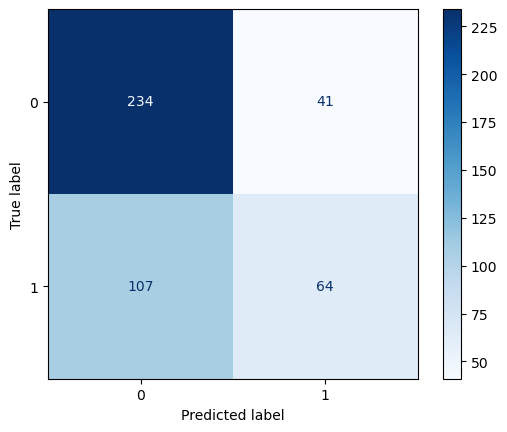

In [139]:
ConfusionMatrixDisplay.from_estimator(model, x_test, y_test, cmap='Blues')

In [140]:
# another way

In [141]:
y_pred = model.predict(x_test)

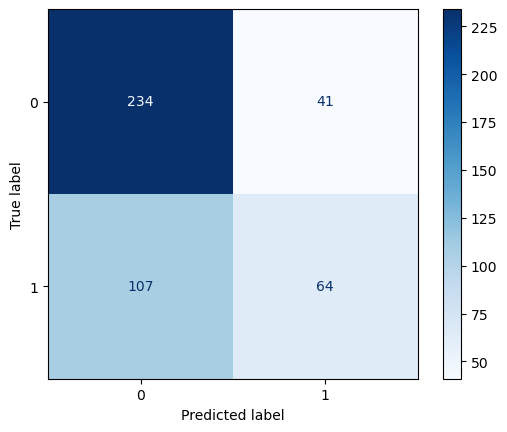

In [142]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap='Blues')

## Trick 8: ROC Curve

In [143]:
from sklearn.metrics import RocCurveDisplay

In [144]:
df = pd.read_csv('Datas/Titanic.csv')
x = df[['Pclass', 'Fare', 'SibSp']]
y = df['Survived']

In [145]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

In [146]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, stratify=y)

In [147]:
lr = LogisticRegression()
dt = DecisionTreeClassifier()
rf = RandomForestClassifier()

lr.fit(x_train, y_train)
dt.fit(x_train, y_train)
rf.fit(x_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

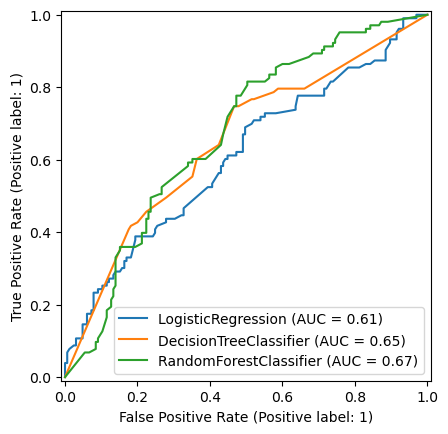

In [148]:
disp = RocCurveDisplay.from_estimator(lr, x_test, y_test)
RocCurveDisplay.from_estimator(dt, x_test, y_test, ax=disp.ax_)
RocCurveDisplay.from_estimator(rf, x_test, y_test, ax=disp.ax_)

## Trick 9: Passthrough and Drop in ColumnTransformer

In [149]:
from sklearn.impute import SimpleImputer
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder

In [150]:
df = pd.read_csv('Datas/Titanic.csv')
df.sample(5)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
126,127,0,3,"McMahon, Mr. Martin",male,NaN,0,0,370372,7.7500,NaN,Q
392,393,0,3,"Gustafsson, Mr. Johan Birger",male,28.0,2,0,3101277,7.9250,NaN,S
394,395,1,3,"Sandstrom, Mrs. Hjalmar (Agnes Charlotta Bengt...",female,24.0,0,2,PP 9549,16.7000,G6,S
697,698,1,3,"Mullens, Miss. Katherine ""Katie""",female,NaN,0,0,35852,7.7333,NaN,Q
110,111,0,1,"Porter, Mr. Walter Chamberlain",male,47.0,0,0,110465,52.0000,C110,S


In [151]:
df = df.dropna(subset='Embarked')
df.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
dtype: int64

In [152]:
ct = make_column_transformer(
    (SimpleImputer(), ['Age']),
    (OneHotEncoder(), ['Embarked']),
    ('passthrough', ['Survived', 'Sex'])
    , remainder='drop'
    )

In [153]:
ct.fit_transform(df)

array([[22.0, 0.0, 0.0, 1.0, 0, 'male'],
       [38.0, 1.0, 0.0, 0.0, 1, 'female'],
       [26.0, 0.0, 0.0, 1.0, 1, 'female'],
       ...,
       [29.64209269662921, 0.0, 0.0, 1.0, 0, 'female'],
       [26.0, 1.0, 0.0, 0.0, 1, 'male'],
       [32.0, 0.0, 1.0, 0.0, 0, 'male']], shape=(889, 6), dtype=object)

In [154]:
ct2 = make_column_transformer(
    (SimpleImputer(), ['Age']),
    (OneHotEncoder(), ['Embarked']),
    ('drop', ['Name', 'PassengerId']),
    remainder='passthrough'
)

In [155]:
ct2.fit_transform(df)

array([[22.0, 0.0, 0.0, ..., 'A/5 21171', 7.25, nan],
       [38.0, 1.0, 0.0, ..., 'PC 17599', 71.2833, 'C85'],
       [26.0, 0.0, 0.0, ..., 'STON/O2. 3101282', 7.925, nan],
       ...,
       [29.64209269662921, 0.0, 0.0, ..., 'W./C. 6607', 23.45, nan],
       [26.0, 1.0, 0.0, ..., '111369', 30.0, 'C148'],
       [32.0, 0.0, 1.0, ..., '370376', 7.75, nan]],
      shape=(889, 12), dtype=object)

## Trick 10: Encoding Categorical Features

In [156]:
# ordinal or not?

In [157]:
from sklearn.preprocessing import OneHotEncoder , OrdinalEncoder

In [158]:
df = pd.DataFrame({
    "education": ["High School", "Bachelor", "Master", "PhD", "Bachelor",
                  "High School", "Master", "PhD", "Bachelor", "Master"],
    "size": ["S", "M", "L", "XL", "M", "S", "L", "M", "XL", "S"],
    "city": ["Tehran", "Berlin", "Munich", "Tehran", "Berlin",
             "Munich", "Tehran", "Berlin", "Munich", "Tehran"],
    "color": ["red", "blue", "green", "red", "green",
              "blue", "red", "green", "blue", "red"],
    "age": [18, 25, 31, 40, 27, 19, 35, 42, 29, 33],
    "target": [0, 1, 1, 1, 0, 0, 1, 1, 0, 1],
})
df

,education,size,city,color,age,target
0,High School,S,Tehran,red,18,0
1,Bachelor,M,Berlin,blue,25,1
2,Master,L,Munich,green,31,1
3,PhD,XL,Tehran,red,40,1
4,Bachelor,M,Berlin,green,27,0
5,High School,S,Munich,blue,19,0
6,Master,L,Tehran,red,35,1
7,PhD,M,Berlin,green,42,1
8,Bachelor,XL,Munich,blue,29,0
9,Master,S,Tehran,red,33,1


In [159]:
ohe = OneHotEncoder()
oe = OrdinalEncoder(categories=[['S', 'M', 'L', 'XL'], ['High School', 'Bachelor', 'Master', 'PhD']])

In [160]:
pd.DataFrame(ohe.fit_transform(df[['city', 'color']]).toarray(), columns=ohe.get_feature_names_out())

,city_Berlin,city_Munich,city_Tehran,color_blue,color_green,color_red
0,0.0,0.0,1.0,0.0,0.0,1.0
1,1.0,0.0,0.0,1.0,0.0,0.0
2,0.0,1.0,0.0,0.0,1.0,0.0
3,0.0,0.0,1.0,0.0,0.0,1.0
4,1.0,0.0,0.0,0.0,1.0,0.0
5,0.0,1.0,0.0,1.0,0.0,0.0
6,0.0,0.0,1.0,0.0,0.0,1.0
7,1.0,0.0,0.0,0.0,1.0,0.0
8,0.0,1.0,0.0,1.0,0.0,0.0
9,0.0,0.0,1.0,0.0,0.0,1.0


In [161]:
oe.fit_transform(df[['size', 'education']])

array([[0., 0.],
       [1., 1.],
       [2., 2.],
       [3., 3.],
       [1., 1.],
       [0., 0.],
       [2., 2.],
       [1., 3.],
       [3., 1.],
       [0., 2.]])

## Trick 11: Save and Load Model with Joblib

In [162]:
import joblib

In [163]:
df = pd.read_csv('Datas/Titanic.csv')
x = df[['Pclass', 'Fare']]
y = df['Survived']

In [164]:
from sklearn.tree import DecisionTreeClassifier

In [165]:
dt = DecisionTreeClassifier()
dt.fit(x, y)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sampl

In [166]:
joblib.dump(dt, 'Datas/DT_Model.joblib')

['Datas/DT_Model.joblib']

In [167]:
model = joblib.load('Datas/DT_Model.joblib')

In [168]:
# We usualy save Pipelines

## Trick 12: CrossValidation and GridSearch

In [169]:
df = pd.read_csv('Datas/Titanic.csv')
df.sample(5)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
585,586,1,1,"Taussig, Miss. Ruth",female,18.0,0,2,110413,79.6500,E68,S
597,598,0,3,"Johnson, Mr. Alfred",male,49.0,0,0,LINE,0.0000,NaN,S
503,504,0,3,"Laitinen, Miss. Kristina Sofia",female,37.0,0,0,4135,9.5875,NaN,S
95,96,0,3,"Shorney, Mr. Charles Joseph",male,NaN,0,0,374910,8.0500,NaN,S
424,425,0,3,"Rosblom, Mr. Viktor Richard",male,18.0,1,1,370129,20.2125,NaN,S


In [170]:
x = df.drop('Survived', axis=1)
y = df['Survived']

In [171]:
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

In [172]:
# CrossValidation

In [173]:
### Wrong methode

# ct_imputation = ColumnTransformer([
#     ('categorical', SimpleImputer(strategy='most_frequent'), ['Embarked']),
#     ('numerical', SimpleImputer(strategy='mean'), ['Age'])
# ],  remainder='passthrough')
# ct_preprocessing = ColumnTransformer([
#     ('categorical', OneHotEncoder(), ['Sex', 'Embarked']),
#     ('numerical', StandardScaler(), ['Age', 'SibSp', 'Parch', 'Fare', 'Pclass'])
# ]  ,remainder='drop')

# pipeline = Pipeline(steps=[
#     ('imputation', ct_imputation),
#     ('preprocessing', ct_preprocessing),
#     ('model', model)
# ])

In [174]:
pipe_categorical = Pipeline(steps=[
    ('imputation', SimpleImputer(strategy='most_frequent')),
    ('encoding', OneHotEncoder(drop=None))
])
pipe_numerical = Pipeline(steps=[
    ('imputation', SimpleImputer(strategy='mean')),
    ('scaling', StandardScaler())
])

In [175]:
ct_preprocessing = ColumnTransformer([
    ('categorical', pipe_categorical, ['Sex', 'Embarked']),
    ('numerical', pipe_numerical, ['Age', 'SibSp', 'Parch', 'Fare', 'Pclass']),
],
    remainder= 'drop'
)

In [176]:
model = LogisticRegression()

In [177]:
pipeline = Pipeline(steps=[
    ('preprocessing', ct_preprocessing),
    ('model', model)
])

In [178]:
cv = cross_val_score(pipeline, x, y, cv=10, scoring='accuracy')

In [179]:
print(cv)
print(cv.std())
print(cv.mean())

[0.78888889 0.79775281 0.7752809  0.80898876 0.78651685 0.7752809
 0.78651685 0.78651685 0.80898876 0.84269663]
0.019233622841571808
0.7957428214731586


In [180]:
# GridSearch

In [181]:
params = {}
params['preprocessing__numerical__imputation__strategy'] = ['mean', 'median']
params['model__C'] = [0.1, 1, 10]
params['model__penalty'] = ['l1', 'l2']
params['preprocessing__categorical__encoding__drop'] = [None, 'first']

In [182]:
gs = GridSearchCV(pipeline, params, scoring='accuracy')

In [183]:
gs.fit(x, y)

c:\Users\Island\anaconda3\envs\ML-DL\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\Island\anaconda3\envs\ML-DL\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\Island\anaconda3\envs\ML-DL

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...egression())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__C': [0.1, 1, ...], 'model__penalty': ['l1', 'l2'], 'preprocessing__categorical__encoding__drop': [None, 'first'], 'preprocessing__numerical__imputation__strategy': ['mean', 'median']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged::

In [184]:
gs.best_params_

{'model__C': 0.1,
 'model__penalty': 'l2',
 'preprocessing__categorical__encoding__drop': 'first',
 'preprocessing__numerical__imputation__strategy': 'median'}

In [185]:
gs.best_score_

np.float64(0.794620551126734)

## Trick 13: 

## Trick 14: 

## Trick 15: 

## Trick 16: 

## Trick 17: 

## Trick 18: make_pipeline Vs Pipeline (also for CT)

In [186]:
"""
make_pipeline needs no Name in the tuple but Pipeline needs it
"""

'\nmake_pipeline needs no Name in the tuple but Pipeline needs it\n'

## Trick 19: syntethic data - part 1

In [187]:
from sklearn.datasets import make_classification

In [188]:
x, y = make_classification(
    n_samples= 1000, 
    n_features=10,
    n_informative=5,
    n_classes= 2,
    weights= [50],
    random_state=0,
)

In [189]:
x

array([[ 2.32621593, -0.56580513,  3.4434403 , ..., -1.36811642,
         3.43654011, -3.0797751 ],
       [-0.32532079,  1.62472132, -1.54436831, ...,  0.79670664,
         1.51388203, -2.62255031],
       [ 0.24349157,  0.41630212, -0.88060559, ...,  0.51545221,
         1.31920771, -2.64245492],
       ...,
       [-2.22831549,  1.73167744,  2.08215961, ...,  0.77295886,
         2.31981684,  0.22476604],
       [ 2.23059521,  0.56512672, -2.3060687 , ..., -0.18091036,
        -1.49827838, -1.0040583 ],
       [-1.60257196,  0.86191105,  3.45005857, ..., -0.49214582,
         2.20398942,  0.05481831]], shape=(1000, 10))

## Trick 20: syntethic data - part 2

In [190]:
from sklearn.datasets import make_blobs, make_circles, make_moons, make_regression